##### 06_Model evaluation 

1. Import libraries and set file paths 

In [1]:
from pathlib import Path 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch    
from torch import nn
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay 
)

CLASS_NAMES = ['good', 'broken', 'heavyload']
LABELS = [0, 1, 2]

# Support running from either the project root or the notebooks folder.
BASE = Path.cwd()
if not (BASE / "features").is_dir():
    BASE = BASE / "notebooks"

FEATURES = BASE / "features"
MODELS = BASE / "models"
RESULTS = BASE / "results"

# Look for the CNN checkpoint in the project root, then notebooks.
CNN_PATH = BASE.parent / "CocainBot.pth"
if not CNN_PATH.is_file():
    CNN_PATH = BASE / "CocainBot.pth"

# Check that all required inputs exist before starting evaluation.
required_files = [
    FEATURES / "F_test.npy",
    FEATURES / "log_M_test.npy",
    FEATURES / "y_test.npy",
    FEATURES / "test_recordings.npy",
    MODELS / "model1_svm.joblib",
    MODELS / "model1_rf.joblib",
    MODELS / "model1_scaler.joblib",
    CNN_PATH
]

for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")

RESULTS.mkdir(exist_ok=True)

print("Notebook folder:", BASE)
print("CNN checkpoint:", CNN_PATH)

Notebook folder: d:\26_AI_pro\VE3451-Gruppe-4\notebooks
CNN checkpoint: d:\26_AI_pro\VE3451-Gruppe-4\CocainBot.pth


2. Load and check the test features 

In [2]:
# Load the features, true labels and recording names in their saved order.
F_test = np.load(FEATURES / "F_test.npy")
y_test = np.load(FEATURES / "y_test.npy")
test_recordings = np.load(FEATURES / "test_recordings.npy")

# Read the Log-Mel features in slices to reduce memory use.
# These features already use training normalization statistics.
log_M_test = np.load(FEATURES / "log_M_test.npy", mmap_mode="r")

# Check that all arrays describe the same number of test clips.
assert len(F_test) == len(log_M_test) == len(y_test) == len(test_recordings)

# Check the input dimensions expected by the trained models.
assert F_test.shape[1:] == (13,)
assert log_M_test.shape[1:] == (64, 259)
assert y_test.ndim == 1
assert test_recordings.ndim == 1

# Check that the test set is non-empty and contains valid class labels.
assert len(y_test) > 0
assert np.isin(y_test, LABELS).all()

# Validation recordings must not appear in the final test set.
assert not np.isin(test_recordings, ["talking_1", "atmo_medium"]).any()

print("MFCC", F_test.shape)
print("Log-mel:", log_M_test.shape)
print("Clips per class:", np.bincount(y_test, minlength=3))
print("Test recording conditions:", np.unique(test_recordings))


MFCC (1579, 13)
Log-mel: (1579, 64, 259)
Clips per class: [529 519 531]
Test recording conditions: ['atmo_high' 'atmo_low' 'stresstest' 'talking_2' 'talking_3' 'talking_4'
 'whitenoise_low']


3. Predict with SVM and Random forest

In [3]:
# Load the trained models and scaler.
svm = joblib.load(MODELS / "model1_svm.joblib")
rf = joblib.load(MODELS / "model1_rf.joblib")
scaler = joblib.load(MODELS / "model1_scaler.joblib")

# SVM requires the same scaling used during training.
# Do not fit the scaler to the test set, only transform it.
F_test_scaled = scaler.transform(F_test)
svm_pred = svm.predict(F_test_scaled)

# Random forest was trained on unscaled MFCC features.
rf_pred = rf.predict(F_test)

print("SVM predictions:", svm_pred.shape)
print("Random forest predictions:", rf_pred.shape)


SVM predictions: (1579,)
Random forest predictions: (1579,)


4. Defined the CNN and load its weights 

In [5]:
# Use the same CNN architecture as in training.
class CNN(nn.Module):
    def __init__(self, numberOfLayers=3, 
                 numberOfKernels=16,
                 kernelSize=3, 
                 inChannels=1):
        super().__init__()
        self.layers = nn.Sequential()

        for i in range(numberOfLayers):
            self.layers.append(
                nn.Conv2d(inChannels, numberOfKernels, kernelSize, padding=1))
            self.layers.append(nn.ReLU())
            self.layers.append(nn.MaxPool2d(2))
            inChannels = numberOfKernels
            numberOfKernels *= 2

        self.layers.append(nn.Flatten())
        self.layers.append(nn.LazyLinear(3))

    def forward(self, input):
        return self.layers(input)

# Load the saved weights and architecture settings.
checkpoint = torch.load(CNN_PATH, map_location="cpu", weights_only=True)

# Match the training architecture using the saved settings.
cnn = CNN(
    numberOfLayers=checkpoint["numberOfLayers"],
    numberOfKernels=checkpoint["numberOfKernals"],
    kernelSize=checkpoint["kernelSize"])

# Restore trained parameters, including the LazyLinear layer.
cnn.load_state_dict(checkpoint["model_state_dict"], strict=True)

device = torch.device("cpu")
cnn = cnn.to(device)

# Set evaluation mode before making predictions.
cnn.eval()

print("Device:", device)
print("CNN weights loaded successfully.")

Device: cpu
CNN weights loaded successfully.


5. Predict with the CNN in small batches    

In [6]:
# Process a small number of clips at a time to limit memory use.
batch_size = 16
cnn_pred = []

# Gradients are unnecessary because no training is performed.
with torch.no_grad():
    for start in range(0, len(log_M_test), batch_size):
        batch = torch.tensor(log_M_test[start:start + batch_size], dtype=torch.float32)
        
        # Add the channel dimension - (batch, 1, 64, 259).
        batch = batch.unsqueeze(1)
        outputs = cnn(batch)

        # The highest output score determines the predicted class.
        predicted = outputs.argmax(dim=1)

        # Keep predictions in the same order as the test labels.
        cnn_pred.extend(predicted.numpy().tolist())

cnn_pred = np.array(cnn_pred)
print("CNN predictions:", cnn_pred.shape)

CNN predictions: (1579,)


6. Compare overall test performance 

In [7]:
# Evaluate all models against the same test labels.
predictions = {
    "SVM": svm_pred,
    "Random Forest": rf_pred,
    "CNN": cnn_pred}

def calculate_score(y_true, y_pred):
    # Macro averaging gives each of the three classes equal weight.
    # Undefined metric values are assigned 0.
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=LABELS,
        average="macro",
        zero_division=0)

    return {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision_macro": precision,
    "Recall_macro": recall,
    "F1_macro": f1}

rows = []
for name, pred in predictions.items():
    assert pred.shape == y_test.shape
    assert np.isin(pred, LABELS).all()

    rows.append({
        "Model": name,
        **calculate_score(y_test, pred)})

overall_results = pd.DataFrame(rows).set_index("Model")

# Round only for display, save the original values.
display(overall_results.round(3))
overall_results.to_csv(RESULTS / "overall_results.csv")


,Accuracy,Precision_macro,Recall_macro,F1_macro
Model,,,,
SVM,0.643,0.828,0.642,0.640
Random Forest,0.729,0.845,0.731,0.695
CNN,0.987,0.987,0.987,0.987


7. Evaluate each class separately

In [8]:
class_rows = []

for name, pred in predictions.items():
    print("\n" + name)

    print(
        classification_report(
            y_test,
            pred,
            labels=LABELS,
            target_names=CLASS_NAMES,
            digits=3,
            zero_division=0
        )
    )

    # Calculate class-level scores for each model inside the loop.
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        pred,
        labels=LABELS,
        average=None,
        zero_division=0)

    # Save one row per class for the current model.
    for i, class_name in enumerate(CLASS_NAMES):
        class_rows.append({
            "Model": name,
            "Class": class_name,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1": f1[i],
            "Support": support[i]})

class_results = pd.DataFrame(class_rows)
assert len(class_results) == 9

display(class_results.round(3))
class_results.to_csv(RESULTS / "class_results.csv", index=False)


SVM
              precision    recall  f1-score   support

        good      0.484     1.000     0.653       529
      broken      1.000     0.441     0.612       519
   heavyload      1.000     0.486     0.654       531

    accuracy                          0.643      1579
   macro avg      0.828     0.642     0.640      1579
weighted avg      0.827     0.643     0.640      1579


Random Forest
              precision    recall  f1-score   support

        good      0.554     0.981     0.708       529
      broken      0.980     0.954     0.967       519
   heavyload      1.000     0.258     0.410       531

    accuracy                          0.729      1579
   macro avg      0.845     0.731     0.695      1579
weighted avg      0.844     0.729     0.693      1579


CNN
              precision    recall  f1-score   support

        good      0.992     0.975     0.984       529
      broken      0.970     1.000     0.985       519
   heavyload      1.000     0.987     0.993       

,Model,Class,Precision,Recall,F1,Support
0,SVM,good,0.484,1.000,0.653,529
1,SVM,broken,1.000,0.441,0.612,519
2,SVM,heavyload,1.000,0.486,0.654,531
3,Random Forest,good,0.554,0.981,0.708,529
4,Random Forest,broken,0.980,0.954,0.967,519
5,Random Forest,heavyload,1.000,0.258,0.410,531
6,CNN,good,0.992,0.975,0.984,529
7,CNN,broken,0.970,1.000,0.985,519
8,CNN,heavyload,1.000,0.987,0.993,531


8. Plot confusion matrices

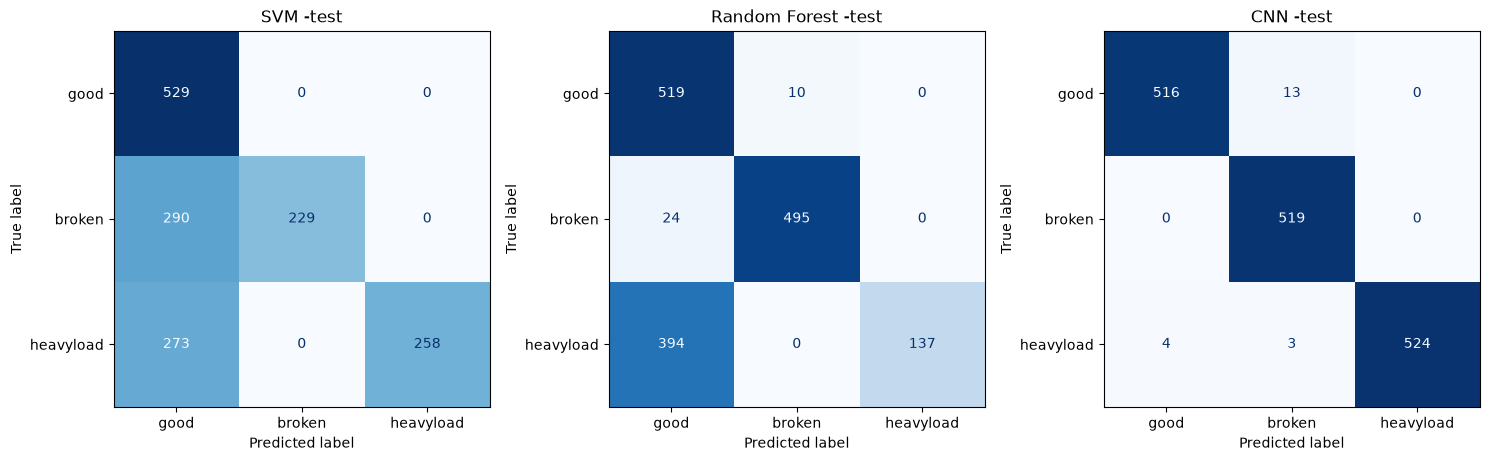

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    ConfusionMatrixDisplay(
        cm,
        display_labels=CLASS_NAMES
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        im_kw={
            "vmin":0,
            "vmax": np.bincount(y_test, minlength=3).max()
        }
    )
    ax.set_title(name + " -test")
    plt.tight_layout()
    plt.savefig(
        RESULTS / "Confusion_matrices.png",
        dpi=200)
plt.show()

9. Compare performance across recording conditions 

,Recording,Model,Clips,Accuracy,Precision_macro,Recall_macro,F1_macro
0,atmo_high,SVM,210,0.333,0.111,0.333,0.167
1,atmo_high,Random Forest,210,0.762,0.861,0.762,0.727
2,atmo_high,CNN,210,1.000,1.000,1.000,1.000
3,atmo_low,SVM,210,1.000,1.000,1.000,1.000
4,atmo_low,Random Forest,210,1.000,1.000,1.000,1.000
5,atmo_low,CNN,210,1.000,1.000,1.000,1.000
6,stresstest,SVM,123,0.805,0.877,0.805,0.809
7,stresstest,Random Forest,123,0.821,0.839,0.821,0.822
8,stresstest,CNN,123,0.837,0.865,0.837,0.837
9,talking_2,SVM,213,0.423,0.456,0.419,0.316


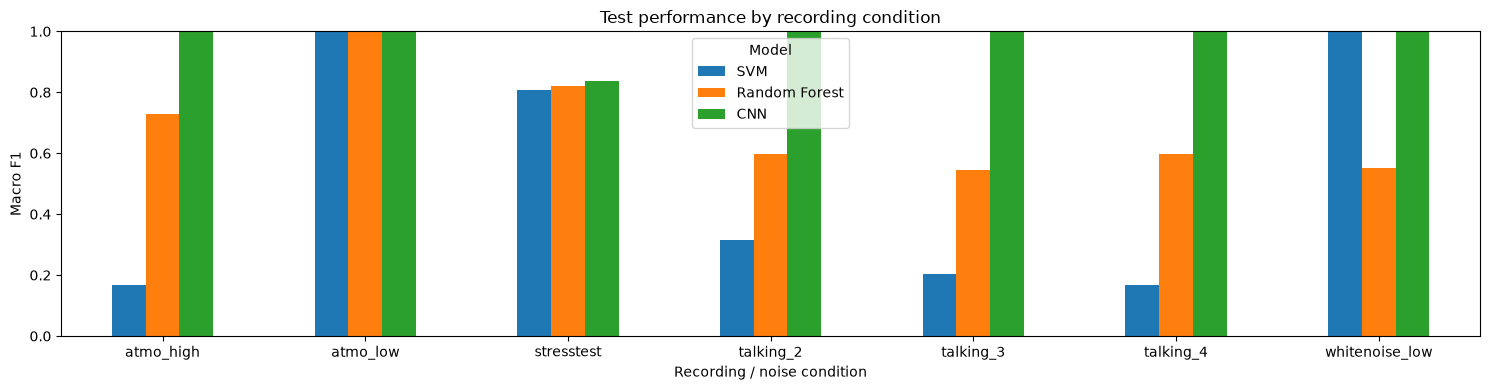

In [10]:
noise_rows=[]

for recording in np.unique(test_recordings):
    mask = test_recordings == recording

    for name, pred in predictions.items():
        noise_rows.append({
            "Recording": recording,
            "Model": name,
            "Clips": int(mask.sum()),
            **calculate_score(y_test[mask], pred[mask])})

noise_results = pd.DataFrame(noise_rows)

display(noise_results.round(3))
noise_results.to_csv(RESULTS / "noise_results.csv", index=False)

# Arrange macro F1 scores for a comparison.
noise_f1 = noise_results.pivot(
    index="Recording",
    columns="Model",
    values="F1_macro")

noise_f1 = noise_f1[list(predictions)]

# Scores are calculated per clip
noise_f1.plot(
    kind="bar",
    figsize=(15,4),
    ylim=(0,1))

plt.ylabel("Macro F1")
plt.xlabel("Recording / noise condition")
plt.title("Test performance by recording condition")
plt.xticks(rotation=0, ha="center")
plt.tight_layout()
plt.savefig(RESULTS / "noise_comparison.png",dpi=200)
plt.show()

10. Save predictions 

In [11]:
prediction_table = pd.DataFrame({
    "Clip_index": np.arange(len(y_test)),
    "Recording": test_recordings,
    "True_label": y_test,
    "SVM_prediction": svm_pred,
    "RF_prediction": rf_pred,
    "CNN_prediction": cnn_pred})

prediction_table.to_csv(RESULTS / "test_predictions.csv", index=False)
print("Saved evaluation results to:", RESULTS)

Saved evaluation results to: d:\26_AI_pro\VE3451-Gruppe-4\notebooks\results
